###  Libraries

In [1]:
# Import libraries
import numpy as np
import torch
import sys
from Datasets.Datasets import get_dataset
from Autoencoder import Autoencoder, CD_Autoencoder
from Visualization import Visualization
from General_Functions import General_Functions

### Global Variables

In [2]:
# Set path to module
path_to_module = './'
sys.path.append(path_to_module)

# Set device (cuda or cpu)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.cuda.set_device(device)

### Visualization

In [3]:
visualization = Visualization()

### Load Dataset

In [4]:
# Set dataset_name, module_name, batch_size and n_clusters
dataset_name = "emnist_balanced_digits" # The available datasets are: emnist_balanced_digits, emnist_mnist, emnist_balanced_letters_A_J, emnist_balanced_letters_K_T, emnist_balanced_letters_U_Z, har, pendigits, waveform_v1, synthetic
batch_size = 256
n_clusters = 10

# Get dataloader, input_dim, data_np and labels
dataloader, input_dim, data_np, labels = get_dataset(dataset_name, batch_size)
print('Data_Shape is:', input_dim)
print('Batches Number is:', len(dataloader))
print(np.unique(labels))

Data_Shape is: 1
Batches Number is: 110
[0 1 2 3 4 5 6 7 8 9]


### Parameters

In [5]:
# Set latent dimension and negative slope
latent_dim = 10
negative_slope = 0

# Set pre-training epochs and learning rate
n_pret_epochs = 100
pret_lr = 1e-3

# Set lamdas, training epochs and learning rate
sil_lambda = 0.01 # 0.01
entr_lambda = 0.01 # 0.01
n_epochs = 100
lr = 5e-4

# Set use_pretrain and is_mlp_ae
use_pretrain = True # Set True for pretraining autoencoder or set False for using already pretrained weights
is_mlp_ae = False # Set True for tabular datasets e.g. pendigits or set False for image datasets e.g. emnist_mnist

### Create Autoencoder Model

In [6]:
if is_mlp_ae:
    autoencoder = Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)
else:
    autoencoder = CD_Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)

autoencoder.set_general_training_variables(dataloader=dataloader, batch_size=batch_size)
autoencoder.set_pretraining_variables(n_pret_epochs=n_pret_epochs, pret_lr=pret_lr)
autoencoder.set_training_variables(n_epochs=n_epochs, lr=lr, sil_lambda=sil_lambda, entr_lambda=entr_lambda)
autoencoder.set_path_variables(path_to_module=path_to_module, dataset_name=dataset_name)
autoencoder.set_path()
autoencoder = autoencoder.to(device)

### Pretrain Autoencoder

In [7]:
if(use_pretrain):
    autoencoder.pretrain_autoencoder()
    autoencoder.save_pretrained_weights()
else:
    model_save_path = autoencoder.data_dir_path + '/Weigths/autoencoder_weights.pth'
    autoencoder.load_state_dict(torch.load(model_save_path))

Epoch: 0, Loss: 59.801524
Epoch: 1, Loss: 37.259128
Epoch: 2, Loss: 25.818806
Epoch: 3, Loss: 17.806599
Epoch: 4, Loss: 12.083789
Epoch: 5, Loss: 8.163764
Epoch: 6, Loss: 5.525966
Epoch: 7, Loss: 3.872660
Epoch: 8, Loss: 2.861230
Epoch: 9, Loss: 2.256314
Epoch: 10, Loss: 1.959147
Epoch: 11, Loss: 1.765900
Epoch: 12, Loss: 1.674777
Epoch: 13, Loss: 1.606443
Epoch: 14, Loss: 1.582132
Epoch: 15, Loss: 1.568858
Epoch: 16, Loss: 1.542695
Epoch: 17, Loss: 1.529273
Epoch: 18, Loss: 1.536099
Epoch: 19, Loss: 1.513871
Epoch: 20, Loss: 1.503754
Epoch: 21, Loss: 1.487038
Epoch: 22, Loss: 1.458609
Epoch: 23, Loss: 1.478530
Epoch: 24, Loss: 1.462350
Epoch: 25, Loss: 1.453064
Epoch: 26, Loss: 1.452155
Epoch: 27, Loss: 1.437851
Epoch: 28, Loss: 1.416010
Epoch: 29, Loss: 1.415081
Epoch: 30, Loss: 1.403242
Epoch: 31, Loss: 1.399416
Epoch: 32, Loss: 1.378935
Epoch: 33, Loss: 1.396843
Epoch: 34, Loss: 1.380015
Epoch: 35, Loss: 1.373307
Epoch: 36, Loss: 1.373247
Epoch: 37, Loss: 1.354031
Epoch: 38, Loss: 

### Initialize the clustering layer using k-means

In [8]:
autoencoder.kmeans_initialization(n_init=100)

ACC: 0.77 PUR: 0.77 NMI: 0.70 ARI: 0.62


### Train Autoencoder

In [9]:
latent_data, labels, clustering = autoencoder.train_autoencoder()

Ep: 0 Rec L: 1.1431 Cl L: 1.1430 Entropy: 3.5681 SSil: -0.0430 ACC: 0.77 PUR: 0.77 NMI: 0.69 ARI: 0.62
Ep: 1 Rec L: 1.1244 Cl L: 1.1576 Entropy: 3.5024 SSil: -0.0576 ACC: 0.77 PUR: 0.77 NMI: 0.69 ARI: 0.61
Ep: 2 Rec L: 1.1400 Cl L: 1.1677 Entropy: 3.4612 SSil: -0.0677 ACC: 0.77 PUR: 0.77 NMI: 0.69 ARI: 0.61
Ep: 3 Rec L: 1.1444 Cl L: 1.1800 Entropy: 3.4136 SSil: -0.0800 ACC: 0.77 PUR: 0.77 NMI: 0.69 ARI: 0.62
Ep: 4 Rec L: 1.1416 Cl L: 1.1965 Entropy: 3.3245 SSil: -0.0965 ACC: 0.78 PUR: 0.78 NMI: 0.71 ARI: 0.64
Ep: 5 Rec L: 1.1935 Cl L: 1.2108 Entropy: 3.1321 SSil: -0.1108 ACC: 0.79 PUR: 0.79 NMI: 0.73 ARI: 0.67
Ep: 6 Rec L: 1.3197 Cl L: 1.1820 Entropy: 2.7540 SSil: -0.0820 ACC: 0.81 PUR: 0.81 NMI: 0.76 ARI: 0.70
Ep: 7 Rec L: 1.4555 Cl L: 1.1073 Entropy: 2.3401 SSil: -0.0073 ACC: 0.83 PUR: 0.83 NMI: 0.80 ARI: 0.74
Ep: 8 Rec L: 1.5266 Cl L: 1.0110 Entropy: 2.0474 SSil: 0.0890 ACC: 0.85 PUR: 0.85 NMI: 0.82 ARI: 0.78
Ep: 9 Rec L: 1.5259 Cl L: 0.9508 Entropy: 1.8909 SSil: 0.1492 ACC: 0.86 PU

### Save Clustering Results

In [10]:
General_Functions().save_excel(autoencoder.data_dir_path, autoencoder.df_eval)

Directory './Results/emnist_balanced_digits/SSAE/100_Eps_ld_10_out_10_bs_256_lr_0.0005_sil_lambda_0.01_entr_lambda_0.01' already exists.


### Plot Clustering Results

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 28010 samples in 0.014s...
[t-SNE] Computed neighbors for 28010 samples in 0.949s...
[t-SNE] Computed conditional probabilities for sample 1000 / 28010
[t-SNE] Computed conditional probabilities for sample 2000 / 28010
[t-SNE] Computed conditional probabilities for sample 3000 / 28010
[t-SNE] Computed conditional probabilities for sample 4000 / 28010
[t-SNE] Computed conditional probabilities for sample 5000 / 28010
[t-SNE] Computed conditional probabilities for sample 6000 / 28010
[t-SNE] Computed conditional probabilities for sample 7000 / 28010
[t-SNE] Computed conditional probabilities for sample 8000 / 28010
[t-SNE] Computed conditional probabilities for sample 9000 / 28010
[t-SNE] Computed conditional probabilities for sample 10000 / 28010
[t-SNE] Computed conditional probabilities for sample 11000 / 28010
[t-SNE] Computed conditional probabilities for sample 12000 / 28010
[t-SNE] Computed conditional probabilities for sam

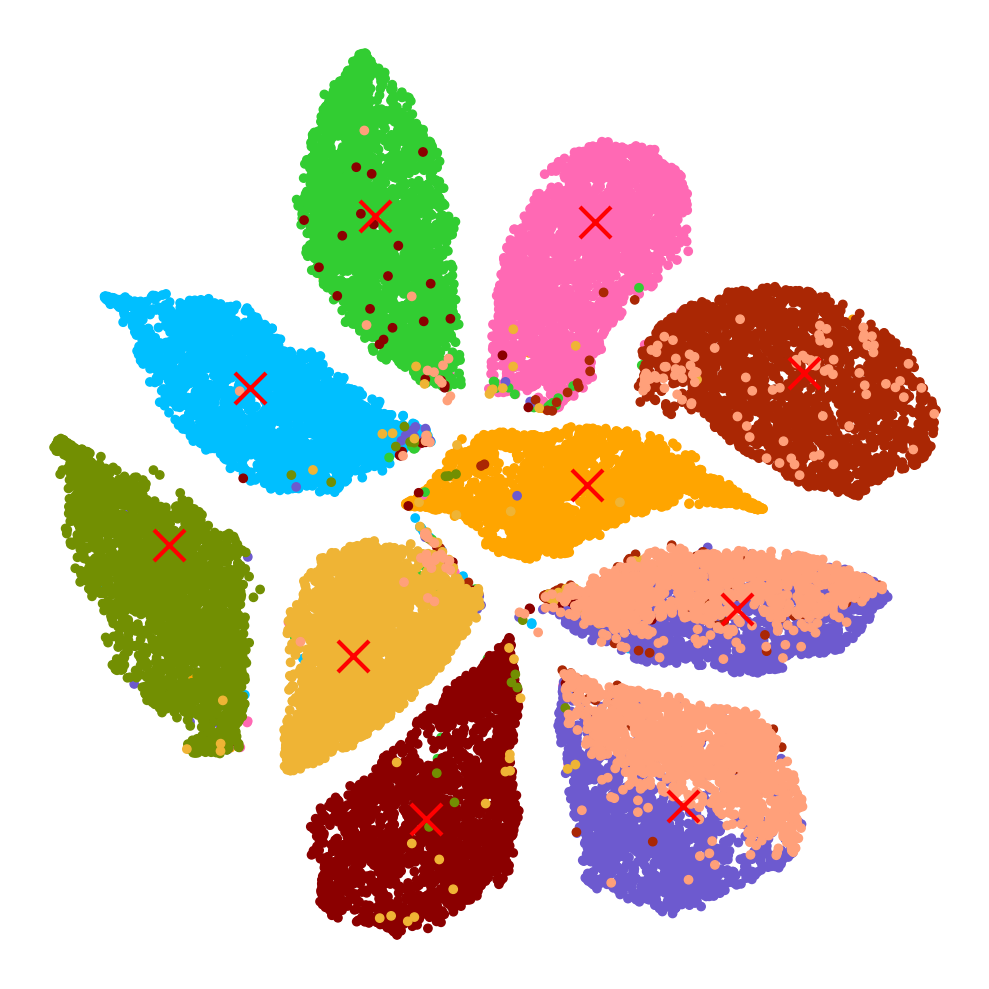

In [11]:
cluster_centers = autoencoder.get_cluster_centers().cpu().detach().numpy()
data, latent_data, labels = autoencoder.get_latent_data()
visualization.plot_tsne(latent_data, labels, clustering, cluster_centers, autoencoder.data_dir_path)